In [1]:
%matplotlib inline
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from lime.lime_tabular import LimeTabularExplainer
import shap
from gps_ids import figures
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Load the dataset
try:
    df = pd.read_csv("../../Datasets/csv/UAVATTACK/spoofing-merged-gps-only.csv")
except FileNotFoundError:
    print("Error: The file '../../Datasets/csv/UAVATTACK/spoofing-merged-gps-only.csv' was not found.")
    print("Please make sure the path is correct.")
    exit()

In [3]:
feature_names = list(df.columns)
print("First 5 rows of the dataset:")
print(df.head())

First 5 rows of the dataset:
   timestamp      q[0]      q[1]      q[2]      q[3]  delta_q_reset[0]  \
0  258725029 -0.325207  0.010554 -0.006518  0.945561          0.999995   
1  258842609 -0.325207  0.010554 -0.006518  0.945561          0.999995   
2  258847608 -0.325207  0.010554 -0.006518  0.945561          0.999995   
3  258852607 -0.325204  0.010556 -0.006517  0.945562          0.999995   
4  258902598 -0.325214  0.010552 -0.006501  0.945559          0.999995   

   delta_q_reset[1]  delta_q_reset[2]  delta_q_reset[3]  quat_reset_counter  \
0     -4.610000e-10      1.580000e-09          0.003237                   3   
1     -4.610000e-10      1.580000e-09          0.003237                   3   
2     -4.610000e-10      1.580000e-09          0.003237                   3   
3     -4.610000e-10      1.580000e-09          0.003237                   3   
4     -4.610000e-10      1.580000e-09          0.003237                   3   

   ...  v_z_valid  xy_reset_counter  z_reset_counte

In [4]:
# Remove 'label' and 'timestamp' from features
feature_names = list(df.columns)
feature_names.remove('label')
if 'timestamp' in feature_names:
    feature_names.remove('timestamp')
X = df[feature_names]
y = df['label']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=100
)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model on scaled data
clf = LogisticRegression()
clf.fit(X_train_scaled, y_train)

/venv/main/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


LogisticRegression()

Intercept 0.4596705304326228
Prediction_local [0.11925974]
Right: 0.007636056592176346
Intercept 0.5403294695673774
Prediction_local [0.88074026]
Right: 0.9923639434078236


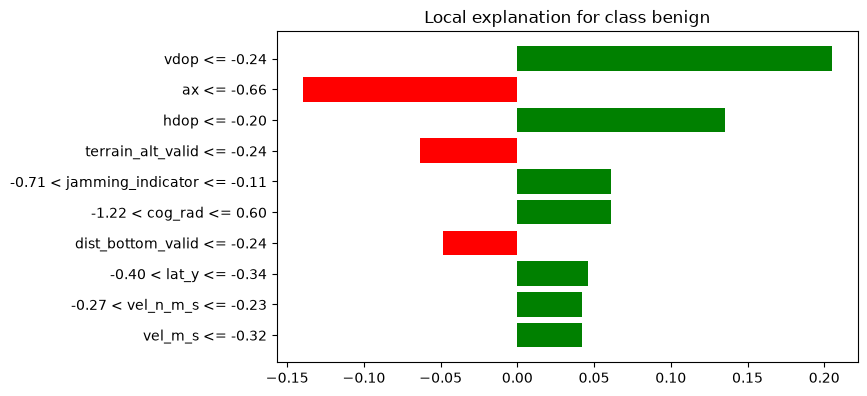

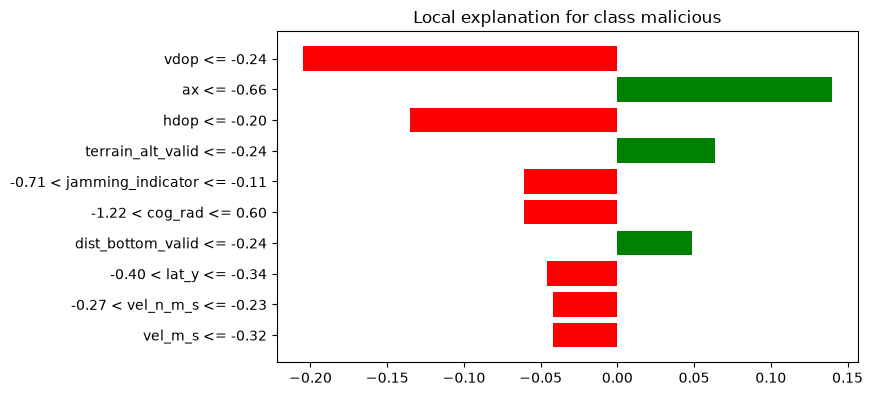

In [7]:
explainer = LimeTabularExplainer(
    training_data=X_train_scaled,
    training_labels=y_train,
    feature_names=feature_names,
    class_names=['benign', 'malicious'],
    kernel_width=3,
    verbose=True,
    mode='classification'
)
instance = X_test_scaled[0]
exp = explainer.explain_instance(instance, clf.predict_proba, top_labels=4)
for class_idx, class_name in enumerate(['benign', 'malicious']):
    fig = exp.as_pyplot_figure(label=class_idx)
    figures.save(f"lime_explanation_{class_name}", fig=fig)
    plt.show()
    plt.close(fig)

In [8]:
for feature, weight in exp.as_list():
    print(f"{feature}: {weight:.4f}")

vdop <= -0.24: -0.2048
ax <= -0.66: 0.1396
hdop <= -0.20: -0.1353
terrain_alt_valid <= -0.24: 0.0635
-0.71 < jamming_indicator <= -0.11: -0.0610
-1.22 < cog_rad <= 0.60: -0.0609
dist_bottom_valid <= -0.24: 0.0486
-0.40 < lat_y <= -0.34: -0.0461
-0.27 < vel_n_m_s <= -0.23: -0.0421
vel_m_s <= -0.32: -0.0419


In [9]:
print(y.unique())

['benign' 'malicious']


Background dataset has 2535 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2535 when initializing the masker.


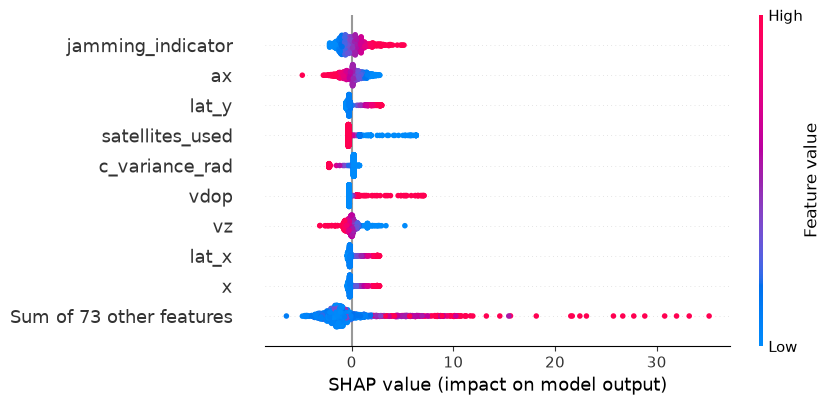

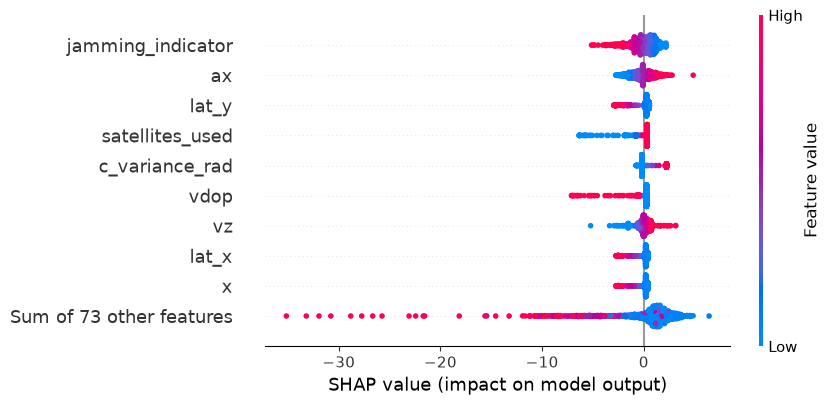

In [10]:
shap.initjs()

shap_explainer = shap.Explainer(clf, X_train_scaled, feature_names=feature_names)
shap_values = shap_explainer(X_test_scaled)

shap.plots.beeswarm(shap_values, show=False)
figures.save("uav_bee_plot_malicious")
plt.show()
plt.close()
# Get SHAP values for 'benign' by flipping the sign
shap_values_benign = shap.Explanation(
    values = -shap_values.values,
    base_values = shap_values.base_values,
    data = shap_values.data,
    feature_names = shap_values.feature_names
)

# Now you can plot or analyze these
shap.plots.beeswarm(shap_values_benign, show=False)
figures.save("uav_bee_plot_benign")
plt.show()
plt.close()

In [11]:
# Get mean absolute SHAP values for each feature
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

top_n = 10  # change this to however many top features you want
top_features_idx = np.argsort(mean_abs_shap)[::-1][:top_n]

# Print the feature names and their importance
print("Top features:")
for idx in top_features_idx:
    print(f"{feature_names[idx]}: {mean_abs_shap[idx]:.4f}")

Top features:
jamming_indicator: 0.8966
ax: 0.7957
lat_y: 0.5381
satellites_used: 0.5336
c_variance_rad: 0.4581
vdop: 0.4187
vz: 0.4063
lat_x: 0.4002
x: 0.4001
s_variance_m_s: 0.3418
